# LDI：Electricity + Solar 多步预测实验
**依据：LDI_Project_Outline_CN.md；适用：Google Colab T4。**

这是一份完整实验 notebook，不是已有实验结果。中文解释/注释，英文图表。
核心：16 通道、过去 48 小时 → 未来 24 小时，两个数据集分别训练。

## 使用顺序
1. Colab → Runtime → Change runtime type → T4 GPU。
2. 顺序执行第 0–9 节。默认包含 2 个简单参考和 6 个学习模型，单种子核心对照。
3. 第 10 节通过独立开关启动多种子/敏感性/消融；默认关闭。
4. 第 11 节导出 CSV、图、SQLite、配置与 checkpoint；不要把未运行项目写成报告成果。

**主要输出**：`runs/<experiment_id>/`、`figures/`、`tables/`、`experiments.sqlite`。
默认挂载 Google Drive 保存结果；原始数据和仓库留在 Colab 本地磁盘加快读取。
全量训练耗时以 T4 实测为准。本 notebook 已配置训练完成跳过和 epoch 边界断线恢复。
改变超参数会生成新实验 ID；手动修改模型代码时务必递增 `IMPLEMENTATION_VERSION`。


## 0. 环境与开关
PyTorch 采用 Colab 已安装版本，不重装 CUDA。仅安装仓库导入所需的轻量依赖。
`reformer-pytorch` 是仓库注意力文件的导入依赖，**本实验不训练 Reformer**。
初次 Colab 挂载 Drive 时需要你操作授权。若不保存到 Drive，可设置 `USE_DRIVE=False`，但会话重置会丢失结果。


In [1]:
import sys, subprocess, importlib.util
for module, package in [('einops', 'einops==0.8.1'), ('reformer_pytorch', 'reformer-pytorch==1.4.4')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import os, json, time, random, hashlib, zipfile, urllib.request, sqlite3, platform
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

USE_DRIVE = True
RUN_CORE = True
RUN_REPEATS = False
RUN_HISTORY = False
RUN_DATA_FRACTION = False
RUN_ABLATION = False
STOP_ON_ERROR = True  # 遇到异常停止，避免把失败误当结果
ALLOW_CPU_TRAINING = False  # 正式训练默认要求 GPU
SEEDS = [42, 123, 2026]
IMPLEMENTATION_VERSION = 'ldi-notebook-v1'
TSLIB_COMMIT = '4e938a1767106324dd753b2a44832bf870a0252e'
DATASETS_TO_RUN = ['Electricity', 'Solar']
CORE_MODELS = ['LSTM', 'GRU', 'CNN', 'CNN_LSTM', 'DLinear', 'PatchTST']
TRAIN_CFG = dict(batch_size=32, max_epochs=20, patience=3, lr=1e-3,
                 weight_decay=1e-4, grad_clip=1.0, dropout=0.1,
                 hidden=64, d_model=64, e_layers=2, n_heads=4,
                 d_ff=128, moving_avg=25, patch_len=16, patch_stride=8)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', platform.python_version(), 'torch:', torch.__version__, 'device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
LOCAL_ROOT = Path('/content/ldi_work') if IN_COLAB else Path.cwd() / 'ldi_work'
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/LDI_Project/results_v1')
else:
    OUTPUT_ROOT = LOCAL_ROOT / 'results_v1'
    print('Results use local storage; back up before resetting the session.')
DATA_DIR = LOCAL_ROOT / 'data'
REPO_DIR = LOCAL_ROOT / 'Time-Series-Library'
for p in [DATA_DIR, OUTPUT_ROOT / 'runs', OUTPUT_ROOT / 'figures', OUTPUT_ROOT / 'tables']:
    p.mkdir(parents=True, exist_ok=True)

def clean_json(x):
    if isinstance(x, dict): return {str(k): clean_json(v) for k,v in x.items()}
    if isinstance(x, (list, tuple)): return [clean_json(v) for v in x]
    if isinstance(x, np.ndarray): return clean_json(x.tolist())
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating, float)): return float(x) if np.isfinite(x) else None
    if isinstance(x, Path): return str(x)
    return x

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(clean_json(obj), ensure_ascii=False, indent=2, allow_nan=False))
    os.replace(tmp, path)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # 保证设置可重复；不同硬件/版本仍可能有差异。

def sync_device():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':180, 'axes.grid':True,
                     'grid.alpha':0.2, 'font.size':10})


Python: 3.13.15 torch: 2.11.0+cu130 device: cuda
GPU: Tesla T4
Mounted at /content/drive


## 1. 固定仓库版本（对应大纲第 3 部分）
仅导入 DLinear/PatchTST 模型类，复用统一训练器；不使用仓库可能不同的数据划分/指标。
commit 固定为编写时核对的版本；不要自动跟随 `main`。如果安装失败，先处理错误，不替换为伪实现。


In [2]:
if not (REPO_DIR / '.git').exists():
    REPO_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.check_call(['git', 'init', str(REPO_DIR)], stdout=subprocess.DEVNULL)
    subprocess.check_call(['git', '-C', str(REPO_DIR), 'remote', 'add', 'origin',
                           'https://github.com/thuml/Time-Series-Library.git'])
    subprocess.check_call(['git', '-C', str(REPO_DIR), 'fetch', '--depth', '1', 'origin', TSLIB_COMMIT])
    subprocess.check_call(['git', '-C', str(REPO_DIR), 'checkout', '--detach', TSLIB_COMMIT])
actual_commit = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert actual_commit == TSLIB_COMMIT, 'Repository version differs. Use a fresh work directory.'
sys.path.insert(0, str(REPO_DIR))
from models.DLinear import Model as OfficialDLinear
from models.PatchTST import Model as OfficialPatchTST
write_json(OUTPUT_ROOT / 'environment.json', dict(
    python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
    pandas=pd.__version__, cuda=torch.version.cuda, tslib_commit=actual_commit,
    device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
    implementation=IMPLEMENTATION_VERSION))
print('Pinned repository:', actual_commit)


Pinned repository: 4e938a1767106324dd753b2a44832bf870a0252e


## 2. 下载、完整性检查与固定 16 通道
原始发布：[Electricity](https://zenodo.org/records/4656140)、[Solar](https://zenodo.org/records/4656144)。
`.tsf` 每行一条序列，转换成 `[time, channel]`。记录实际 SHA-256；检查结构，不假定物理单位。
Solar 来源包含模拟数据。保留记录中的 `00:00:01` 和固定采样间隔，不附加未经核实的时区。


In [10]:
SPECS = {
    'Electricity': dict(stem='electricity_hourly_dataset', record='4656140',
        freq='1h', step_minutes=60, length=26304, total_channels=321,
        start='2012-01-01 00:00:01', ids=['T5','T8','T21','T30','T99','T133','T144','T146',
        'T198','T219','T231','T251','T285','T291','T304','T309']),
    'Solar': dict(stem='solar_10_minutes_dataset', record='4656144',
        freq='10min', step_minutes=10, length=52560, total_channels=137,
        start='2006-01-01 00:00:01', ids=['T7','T9','T27','T28','T41','T58','T60','T64',
        'T69','T77','T82','T97','T115','T123','T127','T131'])}

def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def download_dataset(spec):
    archive_path=DATA_DIR/(spec['stem']+'.zip')
    tsf_path=DATA_DIR/(spec['stem']+'.tsf')
    url=f"https://zenodo.org/records/{spec['record']}/files/{spec['stem']}.zip?download=1"
    if archive_path.exists() and not zipfile.is_zipfile(archive_path):
        print('Invalid cached archive: downloading again', archive_path.name)
        archive_path.unlink()
    if not archive_path.exists():
        tmp=archive_path.with_suffix('.download')
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=90) as response, open(tmp,'wb') as f:
                    import shutil
                    shutil.copyfileobj(response, f)
                with zipfile.ZipFile(tmp) as z:
                    assert z.testzip() is None, 'Corrupt archive'
                os.replace(tmp, archive_path); break
            except Exception:
                tmp.unlink(missing_ok=True)
                if attempt==2: raise
                time.sleep(2**attempt)
    with zipfile.ZipFile(archive_path) as z:
        # 只提取已知 TSF 到明确路径，避免路径穿越或混选数据。
        member=next(n for n in z.namelist() if Path(n).name==tsf_path.name)
        tsf_path.write_bytes(z.read(member))
    return tsf_path

def load_and_audit(name):
    spec=SPECS[name]; path=download_dataset(spec)
    ids=[]; starts=[]; values=[]; metadata={}
    in_data=False
    for line in path.read_text(encoding='utf-8-sig').splitlines():
        line=line.strip()
        if not line or line.startswith('#'): continue
        if line.lower()=='@data': in_data=True; continue
        if not in_data:
            if line.startswith('@'): metadata[line.split()[0]]=line.split()[1:]
            continue
        sid, timestamp, numbers=line.split(':',2)
        assert '?' not in numbers, f'Missing marker: {sid}'
        row=np.asarray(numbers.split(','), dtype=np.float32)
        assert len(row)==spec['length'] and np.isfinite(row).all()
        ids.append(sid); starts.append(timestamp); values.append(row)
    assert len(ids)==spec['total_channels'] and len(set(starts))==1
    start=pd.to_datetime(starts[0],format='%Y-%m-%d %H-%M-%S')
    assert str(start)==spec['start']
    all_values=np.stack(values, axis=1)
    n=len(all_values); b1=int(.7*n); b2=int(.8*n)
    train=all_values[:b1]; valid=np.flatnonzero(train.std(axis=0)>1e-8)
    order=valid[np.argsort(train[:,valid].mean(axis=0),kind='stable')]
    rng=np.random.default_rng(42)
    selected=np.sort(np.concatenate([rng.choice(g,4,replace=False) for g in np.array_split(order,4)]))
    reconstructed=[ids[i] for i in selected]
    assert reconstructed==spec['ids'], f'Subset changed: {reconstructed}'
    data=all_values[:,selected].copy()
    index=pd.date_range(start,periods=n,freq=spec['freq'])
    audit=dict(dataset=name, shape=data.shape, total_channels=len(ids), start=str(start),
               tsf_sha256=file_sha(path), archive_sha256=file_sha(path.with_suffix('.zip')),
               ids=spec['ids'], metadata=metadata, b1=b1, b2=b2,
               missing=False, finite=True, selected_train_constant=False)
    write_json(OUTPUT_ROOT/f'{name}_data_audit.json',audit)
    return dict(raw=data,index=index,spec=spec,b1=b1,b2=b2,audit=audit)

DATA={name:load_and_audit(name) for name in DATASETS_TO_RUN}
display(pd.DataFrame([dict(dataset=k,shape=v['raw'].shape,train_end=str(v['index'][v['b1']-1]),
    validation_end=str(v['index'][v['b2']-1]),test_end=str(v['index'][-1])) for k,v in DATA.items()]))


,dataset,shape,train_end,validation_end,test_end
0,Electricity,"(26304, 16)",2014-02-06 03:00:01,2014-05-26 18:00:01,2014-12-31 23:00:01
1,Solar,"(52560, 16)",2006-09-13 11:50:01,2006-10-19 23:50:01,2006-12-31 23:50:01


## 3. EDA：只用训练区间决定设计
输出一周轨迹、日内模式、相关性和通道统计。Night zeros 不插值。
图表使用原始数据单位；单位未核实前不要写 kW/kWh。
**报告对应**：Datasets / Exploratory Analysis。分析周期与变化，不只堆图。


,series_id,mean,std,min,max,zero_fraction
0,T5,200.024002,69.669609,0.0,547.0,0.000109
1,T8,1032.856567,237.128952,0.0,2018.0,0.000109
2,T21,39.501358,14.659731,0.0,108.0,0.000109
3,T30,148.643433,100.455276,0.0,509.0,0.000109
4,T99,317.985382,102.287445,0.0,890.0,0.000109
5,T133,1119.708740,569.592041,0.0,2559.0,0.000272
6,T144,625.290222,177.744110,8.0,1104.0,0.000000
7,T146,343.151520,122.999252,4.0,652.0,0.000000
8,T198,473.400452,135.389786,8.0,887.0,0.000000
9,T219,230.411362,86.294228,4.0,467.0,0.000000


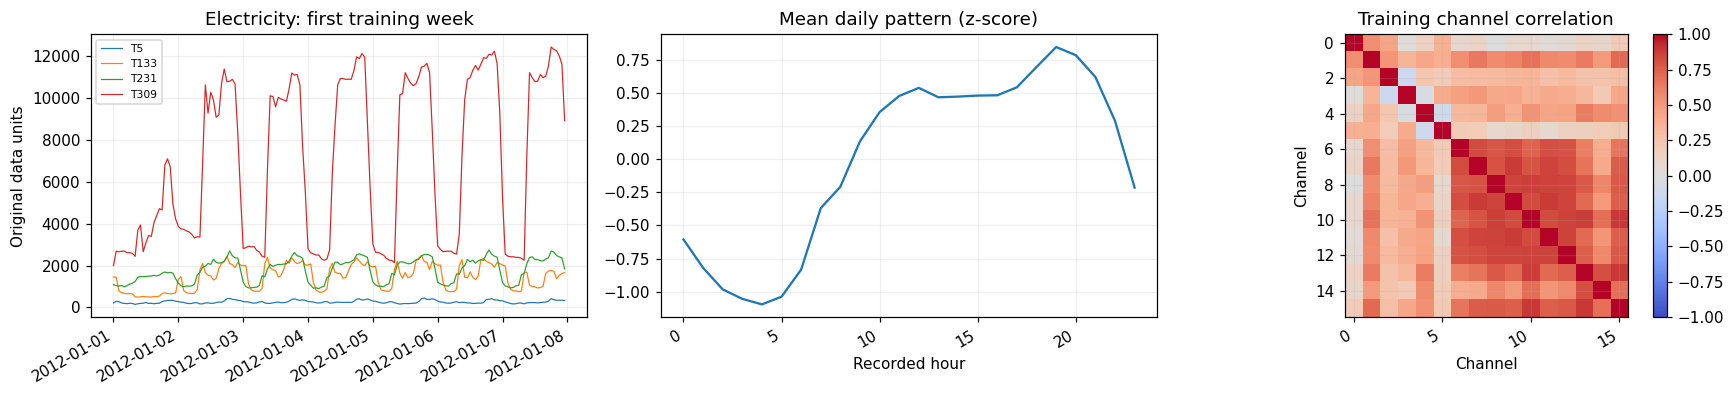

,series_id,mean,std,min,max,zero_fraction
0,T7,5.846290,8.094247,0.0,28.950001,0.531230
1,T9,6.405841,9.078844,0.0,33.400002,0.532942
2,T27,6.046087,8.604268,0.0,31.500000,0.531637
3,T28,6.412065,8.953360,0.0,31.500000,0.532290
4,T41,15.008011,21.480110,0.0,80.650002,0.524380
5,T58,5.709177,8.097261,0.0,29.400000,0.531963
6,T60,6.385922,9.059321,0.0,33.700001,0.532290
7,T64,5.736882,8.091926,0.0,30.450001,0.531121
8,T69,13.465685,17.609823,0.0,59.549999,0.518102
9,T77,6.472809,9.312410,0.0,35.950001,0.532752


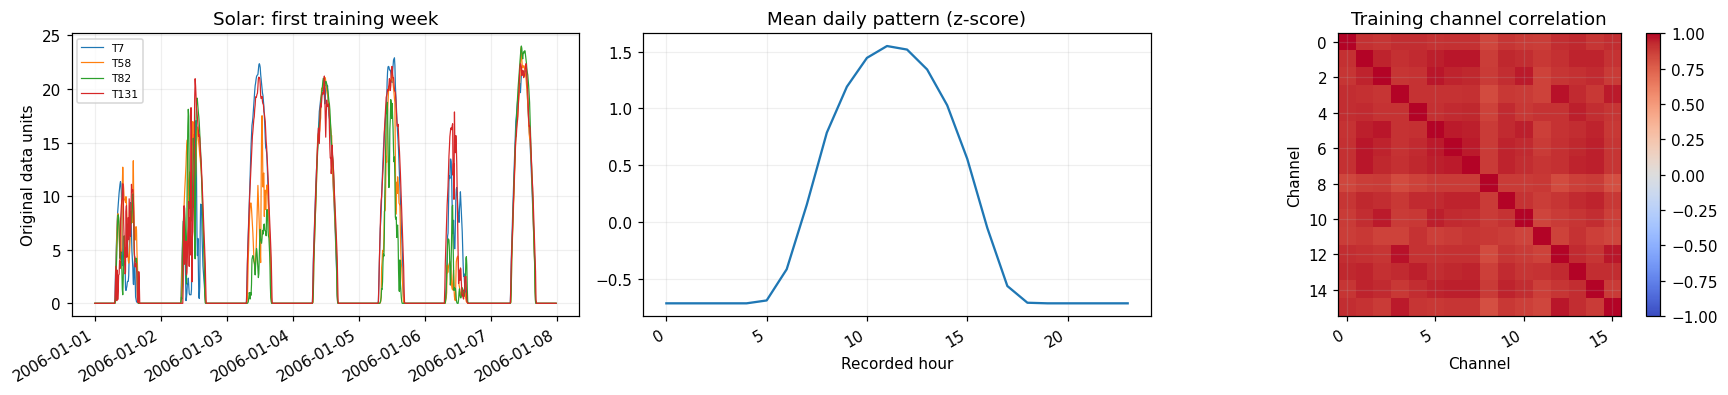

In [11]:
def save_figure(fig,name):
    fig.savefig(OUTPUT_ROOT/'figures'/f'{name}.png',bbox_inches='tight')
    plt.show(); plt.close(fig)

for name,d in DATA.items():
    a=d['raw'][:d['b1']]; idx=d['index'][:d['b1']]; ids=d['spec']['ids']
    statistics=pd.DataFrame({'series_id':ids,'mean':a.mean(0),'std':a.std(0),
        'min':a.min(0),'max':a.max(0),'zero_fraction':(a==0).mean(0)})
    statistics.to_csv(OUTPUT_ROOT/'tables'/f'{name}_training_statistics.csv',index=False)
    display(statistics)
    week=min(len(a),7*24*60//d['spec']['step_minutes'])
    fig,axs=plt.subplots(1,3,figsize=(16,3.7))
    for c in [0,5,10,15]: axs[0].plot(idx[:week],a[:week,c],label=ids[c],lw=.8)
    axs[0].set(title=f'{name}: first training week',ylabel='Original data units'); axs[0].legend(fontsize=7)
    normalized=(a-a.mean(0))/np.maximum(a.std(0),1e-8)
    daily=pd.DataFrame(normalized).groupby(idx.hour).mean().mean(axis=1)
    axs[1].plot(daily.index,daily);axs[1].set(title='Mean daily pattern (z-score)',xlabel='Recorded hour')
    im=axs[2].imshow(np.corrcoef(a.T),vmin=-1,vmax=1,cmap='coolwarm')
    axs[2].set(title='Training channel correlation',xlabel='Channel',ylabel='Channel'); fig.colorbar(im,ax=axs[2])
    fig.autofmt_xdate();fig.tight_layout();save_figure(fig,f'{name}_eda')


## 4. 窗口、scaler 与共同预测起点
训练目标 `[0,b1)`、验证 `[b1,b2)`、测试 `[b2,T)`；完整目标不跨界。
验证/测试输入可用起点前已观测历史，包括前一区间，但不使用当前未来目标，也不更新模型。
敏感性研究会使用最大窗口允许的共同起点。数据比例实验的输入和目标必须全在选定训练片段内。


In [12]:
class WindowDataset(Dataset):
    def __init__(self, scaled, origins, L, H):
        self.scaled=np.asarray(scaled,dtype=np.float32)
        self.origins=np.asarray(origins,dtype=np.int64);self.L=L;self.H=H
    def __len__(self): return len(self.origins)
    def __getitem__(self,i):
        t=int(self.origins[i])
        return torch.from_numpy(self.scaled[t-self.L:t].copy()), torch.from_numpy(self.scaled[t:t+self.H].copy())

def grid_origins(low,high,H,stride):
    first=((int(low)+stride-1)//stride)*stride
    result=np.arange(first,int(high)-H+1,stride,dtype=np.int64)
    assert len(result)>0, 'No valid windows'
    return result

def prepare_context(name,history_hours=48,train_fraction=1.0,common_history_hours=None):
    d=DATA[name];a=d['raw'];b1=d['b1'];b2=d['b2'];step=d['spec']['step_minutes']
    L=int(history_hours*60//step);H=int(24*60//step);period=int(24*60//step)
    common_L=int((common_history_hours or history_hours)*60//step)
    assert common_L>=L and 0<train_fraction<=1
    train_start=b1-int(np.floor(b1*train_fraction))
    train=a[train_start:b1];mu=train.mean(0);sd=train.std(0);sd=np.where(sd<1e-8,1,sd)
    scaled=((a-mu)/sd).astype(np.float32)
    origins={
      'train':grid_origins(train_start+common_L,b1,H,3*60//step),
      'val':grid_origins(max(b1,common_L),b2,H,60//step),
      'test':grid_origins(max(b2,common_L),len(a),H,60//step)}
    for split,os_ in origins.items():
        assert (os_>=L).all()
        low,high={'train':(train_start,b1),'val':(b1,b2),'test':(b2,len(a))}[split]
        assert (os_>=low).all() and (os_+H<=high).all()
        if split=='train': assert (os_-L>=train_start).all()
    denom=np.abs(train[period:]-train[:-period]).mean(0)
    denom=np.where(denom>1e-8,denom,np.nan)
    return dict(name=name,L=L,H=H,period=period,history_hours=history_hours,
        fraction=train_fraction,common_hours=common_history_hours or history_hours,
        train_start=train_start,mu=mu,sd=sd,scaled=scaled,origins=origins,
        mase_denom=denom,peak_threshold=np.quantile(train,.95,axis=0),
        active_threshold=.01*np.maximum(train.max(0),0))

def make_loader(ctx,split,batch_size,shuffle=False):
    ds=WindowDataset(ctx['scaled'],ctx['origins'][split],ctx['L'],ctx['H'])
    return DataLoader(ds,batch_size=batch_size,shuffle=shuffle,num_workers=0,
                      pin_memory=DEVICE.type=='cuda',drop_last=False)

CORE_CONTEXTS={name:prepare_context(name) for name in DATA}
rows=[]
for name,c in CORE_CONTEXTS.items():
    rows.append(dict(dataset=name,L=c['L'],H=c['H'],train=len(c['origins']['train']),
        val=len(c['origins']['val']),test=len(c['origins']['test'])))
    x,y=next(iter(make_loader(c,'train',2)))
    assert x.shape==(2,c['L'],16) and y.shape==(2,c['H'],16)
    recovered=x.numpy()*c['sd']+c['mu'];t=c['origins']['train'][0]
    np.testing.assert_allclose(recovered[0],DATA[name]['raw'][t-c['L']:t],rtol=1e-5,atol=1e-3)
display(pd.DataFrame(rows))


,dataset,L,H,train,val,test
0,Electricity,48,24,6114,2608,5238
1,Solar,288,144,2021,853,1729


## 5. 模型实现
- LSTM/GRU：一层循环编码 + 直接多步头。
- CNN：两层时间卷积 + 4-bin 自适应池化 + 多步头。
- CNN–LSTM：相同 CNN 前端 → LSTM → 多步头。
- DLinear：官方共享通道参数；PatchTST：官方通道独立共享编码。

卷积仅作用在已观测的历史窗口，使用对称 padding 不会读取未来目标。
移除 CNN 的消融相当于 LSTM，需要说明容量/优化差异，不视为完美因果证明。


In [13]:
class RecurrentForecast(nn.Module):
    def __init__(self,kind,H,C=16,hidden=64,dropout=.1):
        super().__init__();self.H=H;self.C=C
        cls=nn.LSTM if kind=='LSTM' else nn.GRU
        self.encoder=cls(C,hidden,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,H*C))
    def forward(self,x):
        output,_=self.encoder(x)
        return self.head(output[:,-1]).reshape(-1,self.H,self.C)

class TemporalCNN(nn.Module):
    def __init__(self,C=16,width=64,dropout=.1):
        super().__init__()
        self.net=nn.Sequential(nn.Conv1d(C,32,9,padding=4),nn.ReLU(),
            nn.Conv1d(32,width,5,padding=2),nn.ReLU(),nn.Dropout(dropout))
    def forward(self,x): return self.net(x.transpose(1,2)).transpose(1,2)

class CNNForecast(nn.Module):
    def __init__(self,H,C=16,hidden=64,dropout=.1):
        super().__init__();self.H=H;self.C=C
        self.encoder=TemporalCNN(C,hidden,dropout)
        self.pool=nn.AdaptiveAvgPool1d(4)
        self.head=nn.Linear(hidden*4,H*C)
    def forward(self,x):
        z=self.pool(self.encoder(x).transpose(1,2)).flatten(1)
        return self.head(z).reshape(-1,self.H,self.C)

class HybridForecast(nn.Module):
    def __init__(self,H,C=16,hidden=64,dropout=.1):
        super().__init__();self.H=H;self.C=C
        self.conv=TemporalCNN(C,hidden,dropout)
        self.encoder=nn.LSTM(hidden,hidden,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,H*C))
    def forward(self,x):
        out,_=self.encoder(self.conv(x))
        return self.head(out[:,-1]).reshape(-1,self.H,self.C)

class RepositoryWrapper(nn.Module):
    def __init__(self,model): super().__init__();self.model=model
    def forward(self,x):
        # 官方模型此预测路径不需要未来输入/时间标记，避免信息不一致。
        return self.model(x,None,None,None)

def build_model(name,ctx,cfg):
    kw=dict(H=ctx['H'],hidden=cfg['hidden'],dropout=cfg['dropout'])
    if name in ['LSTM','GRU']: return RecurrentForecast(name,**kw)
    if name in ['CNN','CNN_LSTM_noCNN']: return CNNForecast(**kw) if name=='CNN' else RecurrentForecast('LSTM',**kw)
    if name=='CNN_LSTM': return HybridForecast(**kw)
    args=SimpleNamespace(task_name='long_term_forecast',seq_len=ctx['L'],pred_len=ctx['H'],
        enc_in=16,moving_avg=cfg['moving_avg'],d_model=cfg['d_model'],d_ff=cfg['d_ff'],
        e_layers=cfg['e_layers'],n_heads=cfg['n_heads'],dropout=cfg['dropout'],factor=5,activation='gelu')
    if name=='DLinear': return RepositoryWrapper(OfficialDLinear(args,individual=False))
    if name=='PatchTST':
        assert ctx['L']>=cfg['patch_len']
        return RepositoryWrapper(OfficialPatchTST(args,patch_len=cfg['patch_len'],stride=cfg['patch_stride']))
    raise ValueError(name)


## 6. 指标与工程条件评价
每通道 MAE/RMSE 再 macro-average，另报 pooled RMSE（两者不是同一指标）。
MASE 分母用对应训练片段日周期差分；无效分母计数，不用任意 epsilon 掩盖。
前 4 小时是 24 小时模型的输出切片，不是另一个训练任务。
Solar active mask = 真实出力 > 训练最大出力的 1%；只能用于事后评价，**不叫天文白天**。
Electricity peak mask = 真实目标 > 训练 95% 分位数。报告覆盖率，不按测试效果挑阈值。


In [14]:
def error_summary(pred,true,ctx,mask=None):
    assert pred.shape==true.shape and pred.ndim==3
    assert np.isfinite(pred).all() and np.isfinite(true).all()
    error=pred.astype(np.float64)-true.astype(np.float64)
    selected=np.ones(true.shape,dtype=bool) if mask is None else np.broadcast_to(mask,true.shape)
    count=selected.sum(axis=(0,1));safe=np.maximum(count,1)
    mae=(np.abs(error)*selected).sum(axis=(0,1))/safe
    rmse=np.sqrt(((error**2)*selected).sum(axis=(0,1))/safe)
    mae[count==0]=np.nan;rmse[count==0]=np.nan
    mase=mae/ctx['mase_denom']
    def avg(a): return float(np.nanmean(a)) if np.isfinite(a).any() else np.nan
    macro=dict(MAE=avg(mae),RMSE=avg(rmse),MASE=avg(mase),
        pooled_RMSE=float(np.sqrt(((error**2)*selected).sum()/selected.sum())) if selected.any() else np.nan,
        coverage=float(selected.mean()),n_values=int(selected.sum()),
        undefined_MASE_channels=int((~np.isfinite(mase)).sum()))
    channels=pd.DataFrame({'series_id':DATA[ctx['name']]['spec']['ids'],
        'MAE':mae,'RMSE':rmse,'MASE':mase,'n_values':count})
    return macro,channels

def evaluate_arrays(pred,true,origins,ctx,outdir):
    metrics,channels=error_summary(pred,true,ctx)
    channels.to_csv(outdir/'per_channel.csv',index=False)
    error=pred.astype(np.float64)-true.astype(np.float64)
    lead=pd.DataFrame({'lead_hours':np.arange(1,ctx['H']+1)*DATA[ctx['name']]['spec']['step_minutes']/60,
        'MAE':np.abs(error).mean(axis=(0,2)),
        'RMSE':np.sqrt((error**2).mean(axis=(0,2)))})
    lead.to_csv(outdir/'lead_time.csv',index=False)
    first4=int(4*60//DATA[ctx['name']]['spec']['step_minutes'])
    first_mask=np.arange(ctx['H'])[None,:,None]<first4
    masks={'first_4h':first_mask,'full_24h':np.ones((1,ctx['H'],1),bool)}
    positions=origins[:,None]+np.arange(ctx['H'])[None,:]
    weekend=np.asarray(DATA[ctx['name']]['index'].dayofweek)[positions]>=5
    masks.update(weekday=(~weekend)[...,None],weekend=weekend[...,None])
    if ctx['name']=='Solar':
        active=true>ctx['active_threshold'][None,None,:]
        masks.update(active_output=active,low_output=~active)
        metrics['negative_prediction_fraction']=float((pred<0).mean())
    else:
        masks['load_peak']=true>ctx['peak_threshold'][None,None,:]
    rows=[]
    for condition,mask in masks.items():
        values,_=error_summary(pred,true,ctx,mask)
        rows.append(dict(condition=condition,**values))
    pd.DataFrame(rows).to_csv(outdir/'conditional.csv',index=False)
    metrics['first4h_MAE']=rows[0]['MAE']
    write_json(outdir/'metrics.json',metrics)
    return metrics


## 7. 统一训练器、断线恢复与数据库
每个 epoch 保存 `last.pt`（模型、optimizer、RNG、早停状态）；`best.pt` 用验证集 MSE 选择。
只恢复本 notebook 写出的可信 checkpoint。断线发生在 epoch 内时，重做该 epoch；不伪装成 batch 级精确恢复。
完成实验有配置 hash，重跑会跳过；失败会记录状态并默认停止。恢复耗时另报本次/累计时间。


In [15]:
DB_PATH=OUTPUT_ROOT/'experiments.sqlite'
with sqlite3.connect(DB_PATH) as conn:
    conn.execute('CREATE TABLE IF NOT EXISTS experiments (experiment_id TEXT PRIMARY KEY, status TEXT, config_json TEXT, result_json TEXT, run_path TEXT, updated TEXT)')

def register_run(runid,status,spec,result=None):
    with sqlite3.connect(DB_PATH) as conn:
        conn.execute('INSERT OR REPLACE INTO experiments VALUES (?,?,?,?,?,?)',
            (runid,status,json.dumps(clean_json(spec)),json.dumps(clean_json(result or {})),
             str(OUTPUT_ROOT/'runs'/runid),pd.Timestamp.now(tz='UTC').isoformat()))

def atomic_torch_save(obj,path):
    tmp=Path(str(path)+'.tmp');torch.save(obj,tmp);os.replace(tmp,path)

def load_checkpoint(path):
    # 仅加载我们生成的 checkpoint（含 optimizer/RNG，不是第三方上传）。
    return torch.load(path,map_location=DEVICE,weights_only=False)

def run_spec(model,ctx,seed,stage,cfg):
    origins_hash=hashlib.sha256(b''.join(ctx['origins'][s].tobytes() for s in ['train','val','test'])).hexdigest()
    return dict(dataset=ctx['name'],model=model,seed=seed,stage=stage,
        history_hours=ctx['history_hours'],train_fraction=ctx['fraction'],
        common_history_hours=ctx['common_hours'],L=ctx['L'],H=ctx['H'],
        train_start=ctx['train_start'],b1=DATA[ctx['name']]['b1'],b2=DATA[ctx['name']]['b2'],
        ids=DATA[ctx['name']]['spec']['ids'],data_sha=DATA[ctx['name']]['audit']['tsf_sha256'],
        origins_hash=origins_hash,tslib_commit=TSLIB_COMMIT,implementation=IMPLEMENTATION_VERSION,
        config=cfg,torch_version=str(torch.__version__),device=str(DEVICE),
        scaler_mu=ctx['mu'].tolist(),scaler_sd=ctx['sd'].tolist())

@torch.no_grad()
def validation_loss(model,loader):
    model.eval();total=0.;count=0
    for x,y in loader:
        x=x.to(DEVICE);y=y.to(DEVICE)
        p=model(x)
        assert p.shape==y.shape
        loss=(p-y).square()
        assert torch.isfinite(loss).all(), 'Non-finite validation loss'
        total+=loss.sum().item();count+=loss.numel()
    return total/count

@torch.no_grad()
def predict_neural(model,ctx,batch_size):
    model.eval();parts=[]
    for x,_ in make_loader(ctx,'test',batch_size):
        p=model(x.to(DEVICE)).float().cpu().numpy()
        assert p.shape[1:]==(ctx['H'],16) and np.isfinite(p).all()
        parts.append(p*ctx['sd']+ctx['mu'])
    return np.concatenate(parts).astype(np.float32)

@torch.no_grad()
def inference_benchmark(model,ctx,batch_size,repeats=10):
    x,_=next(iter(make_loader(ctx,'test',batch_size)))
    x=x.to(DEVICE);model.eval()
    for _ in range(3): model(x)
    sync_device();start=time.perf_counter()
    for _ in range(repeats):model(x)
    sync_device()
    return dict(inference_ms_per_batch=(time.perf_counter()-start)*1000/repeats,
                inference_batch_size=len(x),inference_includes_transfer=False)

def train_model(model,ctx,cfg,outdir):
    model.to(DEVICE);optimizer=torch.optim.Adam(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    train_loader=make_loader(ctx,'train',cfg['batch_size'],True)
    val_loader=make_loader(ctx,'val',cfg['batch_size'])
    start_epoch=0;best=float('inf');bad=0;history=[];cumulative=0.;previous_peak=0.
    if (outdir/'last.pt').exists():
        state=load_checkpoint(outdir/'last.pt');model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer']);start_epoch=state['epoch']+1
        best=state['best'];bad=state['bad'];history=state['history'];cumulative=state['train_seconds']
        previous_peak=state.get('peak_memory_mb',0.)
        random.setstate(state['python_rng']);np.random.set_state(state['numpy_rng'])
        torch.set_rng_state(state['torch_rng'].cpu())
        if DEVICE.type=='cuda' and state['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda_rng']])
        print('Resume at epoch',start_epoch+1)
    if DEVICE.type=='cuda':torch.cuda.reset_peak_memory_stats()
    invocation_seconds=0.
    for epoch in range(start_epoch,cfg['max_epochs']):
        if bad>=cfg['patience']:break
        model.train();sync_device();start=time.perf_counter();loss_sum=0.;nvalues=0
        for x,y in train_loader:
            x=x.to(DEVICE);y=y.to(DEVICE);optimizer.zero_grad(set_to_none=True)
            p=model(x);assert p.shape==y.shape
            loss=(p-y).square().mean()
            if not torch.isfinite(loss):raise RuntimeError('Non-finite training loss')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),cfg['grad_clip']);optimizer.step()
            loss_sum+=loss.item()*y.numel();nvalues+=y.numel()
        val=validation_loss(model,val_loader);sync_device()
        seconds=time.perf_counter()-start;cumulative+=seconds;invocation_seconds+=seconds
        improved=val<best-1e-8
        if improved:
            best=val;bad=0;atomic_torch_save(model.state_dict(),outdir/'best.pt')
        else:bad+=1
        history.append(dict(epoch=epoch+1,train_MSE=loss_sum/nvalues,val_MSE=val,epoch_seconds=seconds))
        pd.DataFrame(history).to_csv(outdir/'history.csv',index=False)
        peak=max(previous_peak,torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0.)
        atomic_torch_save(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),epoch=epoch,
            best=best,bad=bad,history=history,train_seconds=cumulative,peak_memory_mb=peak,
            python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None),outdir/'last.pt')
        print(f'epoch {epoch+1:02d}: train={history[-1]["train_MSE"]:.5f}, val={val:.5f}, {seconds:.1f}s')
    assert (outdir/'best.pt').exists(), 'No best checkpoint'
    model.load_state_dict(load_checkpoint(outdir/'best.pt'));model.eval()
    return dict(train_seconds=cumulative,this_invocation_train_seconds=invocation_seconds,
        epochs=len(history),best_val_MSE=best,
        peak_training_memory_mb=max(previous_peak,torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0.))

def run_experiment(model_name,ctx,seed=42,stage='core',cfg=None):
    cfg=dict(TRAIN_CFG if cfg is None else cfg);spec=run_spec(model_name,ctx,seed,stage,cfg)
    digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
    grouping_spec={k:v for k,v in spec.items() if k!='seed'}
    comparison_key=hashlib.sha256(json.dumps(grouping_spec,sort_keys=True).encode()).hexdigest()[:16]
    runid=f'{ctx["name"]}_{model_name}_{stage}_s{seed}_{digest}'
    outdir=OUTPUT_ROOT/'runs'/runid;outdir.mkdir(parents=True,exist_ok=True)
    if (outdir/'result.json').exists() and (outdir/'predictions.npz').exists():
        result=json.loads((outdir/'result.json').read_text());register_run(runid,'completed',spec,result)
        print('Skip completed:',runid);return result
    write_json(outdir/'config.json',spec)
    write_json(outdir/'scaler_and_thresholds.json',dict(mu=ctx['mu'],sd=ctx['sd'],mase_denom=ctx['mase_denom'],
        peak_threshold=ctx['peak_threshold'],active_threshold=ctx['active_threshold']))
    register_run(runid,'running',spec);model=None
    try:
        seed_everything(seed);origins=ctx['origins']['test'];raw=DATA[ctx['name']]['raw'];H=ctx['H']
        true=np.stack([raw[t:t+H] for t in origins]);resources={}
        if model_name in ['Persistence','SeasonalNaive']:
            start=time.perf_counter()
            if model_name=='Persistence': pred=np.repeat(raw[origins-1,None,:],H,axis=1)
            else: pred=np.stack([raw[t-ctx['period']:t-ctx['period']+H] for t in origins])
            resources=dict(train_seconds=0.,epochs=0,parameters=0,
                baseline_total_forecast_seconds=time.perf_counter()-start)
        else:
            if DEVICE.type!='cuda' and not ALLOW_CPU_TRAINING:
                raise RuntimeError('Select Colab T4 GPU, or explicitly enable CPU for small checks.')
            model=build_model(model_name,ctx,cfg).to(DEVICE)
            parameters=sum(p.numel() for p in model.parameters())
            x,y=next(iter(make_loader(ctx,'train',2)))
            with torch.no_grad():
                output=model(x.to(DEVICE));assert output.shape==y.shape and torch.isfinite(output).all()
            resources=train_model(model,ctx,cfg,outdir)
            resources.update(parameters=parameters,**inference_benchmark(model,ctx,cfg['batch_size']))
            pred=predict_neural(model,ctx,cfg['batch_size'])
        np.savez_compressed(outdir/'predictions.npz',prediction=pred.astype(np.float32),origins=origins)
        metrics=evaluate_arrays(pred,true,origins,ctx,outdir)
        result=dict(experiment_id=runid,comparison_key=comparison_key,dataset=ctx['name'],model=model_name,stage=stage,seed=seed,
            history_hours=ctx['history_hours'],train_fraction=ctx['fraction'],common_hours=ctx['common_hours'],
            L=ctx['L'],H=ctx['H'],run_path=str(outdir),**resources,**metrics)
        write_json(outdir/'result.json',result);register_run(runid,'completed',spec,result)
        print('Completed:',runid,'MAE=',metrics['MAE']);return result
    except Exception as exc:
        register_run(runid,'failed',spec,dict(error=repr(exc)))
        write_json(outdir/'failure.json',dict(error=repr(exc)))
        if STOP_ON_ERROR:raise
        print('FAILED:',runid,repr(exc));return None
    finally:
        del model
        if DEVICE.type=='cuda':torch.cuda.empty_cache()


## 8. 核心对照（默认运行）
先运行简单参考，再按 LSTM、GRU、CNN、CNN–LSTM、DLinear、PatchTST 顺序。
需要暂时调试时，只改 `DATASETS_TO_RUN` / `CORE_MODELS`，不要改变固定子集或划分来迎合结果。
本单元可能运行较久，每个 epoch 会打印进度。完成的实验不会重复训练。


In [16]:
if RUN_CORE:
    for name in DATASETS_TO_RUN:
        ctx=CORE_CONTEXTS[name]
        for model_name in ['Persistence','SeasonalNaive']+CORE_MODELS:
            print('===',name,model_name,'===')
            run_experiment(model_name,ctx,seed=42,stage='core')
else:
    print('Core training disabled; existing results can still be analysed.')


=== Electricity Persistence ===
Completed: Electricity_Persistence_core_s42_80f32c5513e3 MAE= 1010.2606349234759
=== Electricity SeasonalNaive ===
Completed: Electricity_SeasonalNaive_core_s42_71e6f97333ec MAE= 208.21797093753975
=== Electricity LSTM ===
epoch 01: train=0.51463, val=0.31513, 1.2s
epoch 02: train=0.27556, val=0.23753, 0.7s
epoch 03: train=0.22733, val=0.21802, 0.7s
epoch 04: train=0.20892, val=0.21041, 0.7s
epoch 05: train=0.19753, val=0.20717, 0.7s
epoch 06: train=0.18942, val=0.20202, 0.7s
epoch 07: train=0.18306, val=0.20112, 0.7s
epoch 08: train=0.17844, val=0.19482, 0.7s
epoch 09: train=0.17559, val=0.19752, 0.7s
epoch 10: train=0.17257, val=0.19624, 0.7s
epoch 11: train=0.17011, val=0.19207, 0.7s
epoch 12: train=0.16767, val=0.19185, 0.7s
epoch 13: train=0.16612, val=0.18814, 0.7s
epoch 14: train=0.16409, val=0.18603, 0.7s
epoch 15: train=0.16255, val=0.18822, 0.7s
epoch 16: train=0.16107, val=0.18702, 0.7s
epoch 17: train=0.16085, val=0.18385, 0.7s
epoch 18: trai

## 9. 结果表与报告图
两个数据集分别汇总，不平均不同单位的原尺度误差。模型缺失时明确保留 missing 状态。
报告使用：总表、学习曲线、lead-time、情境误差、成本、固定轨迹和失败案例。
展示 test 第一条、预先定义的峰值/活跃出力起点，以及验证选中模型的最差例；最差例是诊断，不能作为总体性能证明。


,MAE,RMSE,MASE,first4h_MAE,parameters,train_seconds,epochs,status
model,,,,,,,,
Persistence,1010.260635,1321.402613,3.630473,484.910492,0,0.000000,0,completed
SeasonalNaive,208.217971,348.941841,1.008813,208.121614,0,0.000000,0,completed
LSTM,258.517937,353.460007,1.246911,256.961477,45952,14.670802,20,completed
GRU,252.333278,341.724402,1.247105,253.831581,40704,13.422412,20,completed
CNN,255.728609,338.992177,1.261648,249.586448,113632,10.265235,15,completed
CNN_LSTM,266.288502,365.562160,1.300423,265.905325,73184,16.486114,19,completed
DLinear,210.343758,310.779649,0.984451,169.718300,2352,12.254296,20,completed
PatchTST,229.868157,322.709216,1.026148,177.255196,77336,19.072221,9,completed


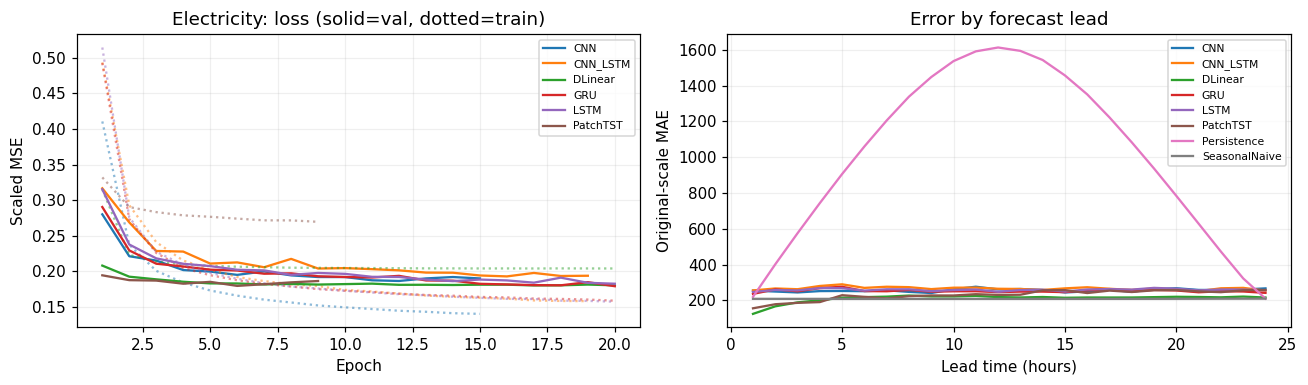

condition,first_4h,full_24h,load_peak,weekday,weekend
model,,,,,
CNN,249.586448,255.728609,505.601164,248.467337,274.028185
CNN_LSTM,265.905325,266.288502,534.310567,254.403137,296.241539
DLinear,169.718300,210.343758,452.510665,194.117081,251.237602
GRU,253.831581,252.333278,528.774841,241.397657,279.892807
LSTM,256.961477,258.517937,594.688040,249.242243,281.894180
PatchTST,177.255196,229.868157,519.004654,211.258220,276.768199
Persistence,484.910492,1010.260635,1448.160026,997.445273,1042.557414
SeasonalNaive,208.121614,208.217971,390.525866,194.647128,242.418683


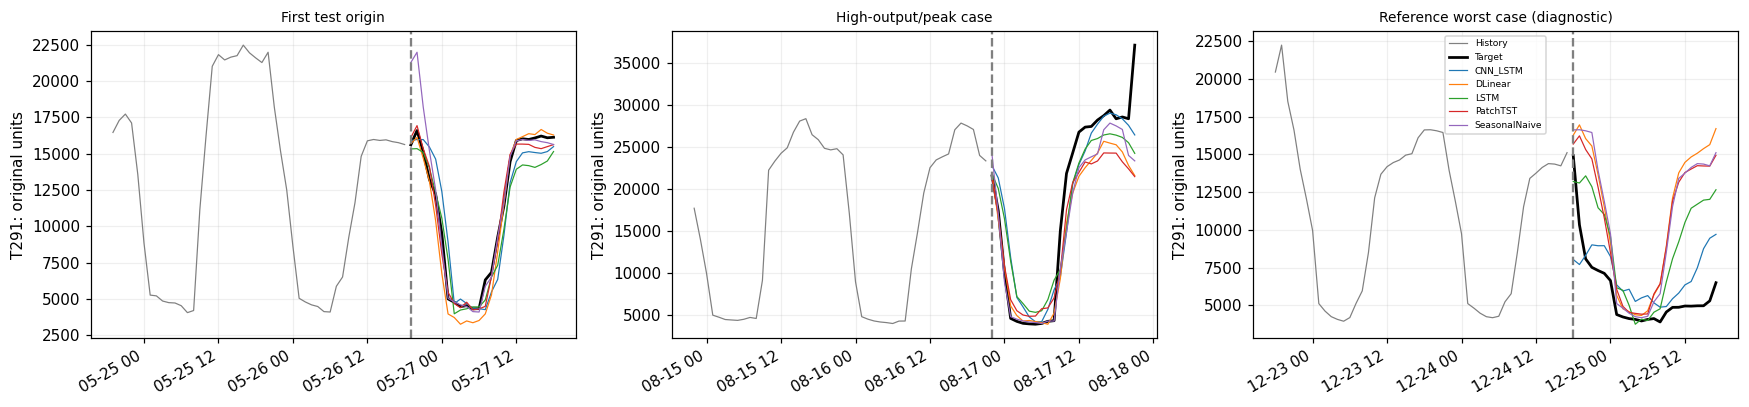

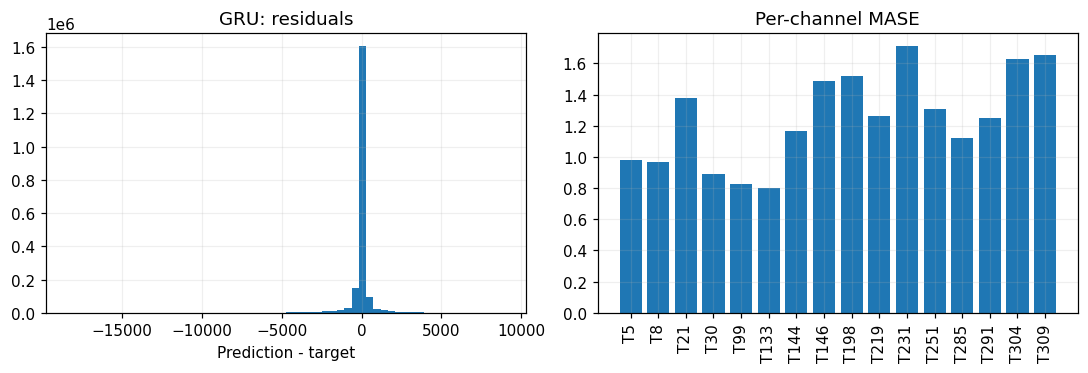

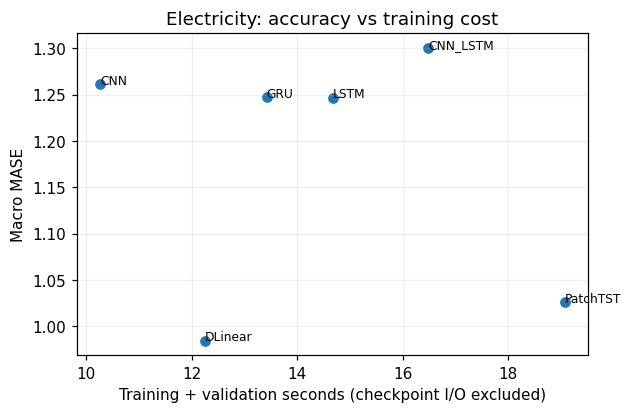

,MAE,RMSE,MASE,first4h_MAE,parameters,train_seconds,epochs,status
model,,,,,,,,
Persistence,7.379444,11.524962,3.047881,3.505219,0,0.000000,0,completed
SeasonalNaive,2.197647,5.244402,0.899621,2.202167,0,0.000000,0,completed
LSTM,3.524112,5.488612,1.441520,2.981308,170752,3.655306,13,completed
GRU,3.130467,5.018550,1.276590,2.796412,165504,3.687848,14,completed
CNN,4.098103,5.406629,1.688072,4.217653,607072,5.325779,20,completed
CNN_LSTM,3.283134,5.292455,1.340408,2.903464,197984,4.752587,13,completed
DLinear,3.175142,4.804990,1.297769,2.482560,83232,1.872769,8,completed
PatchTST,3.117457,4.861096,1.282784,2.617612,400016,15.725467,13,completed


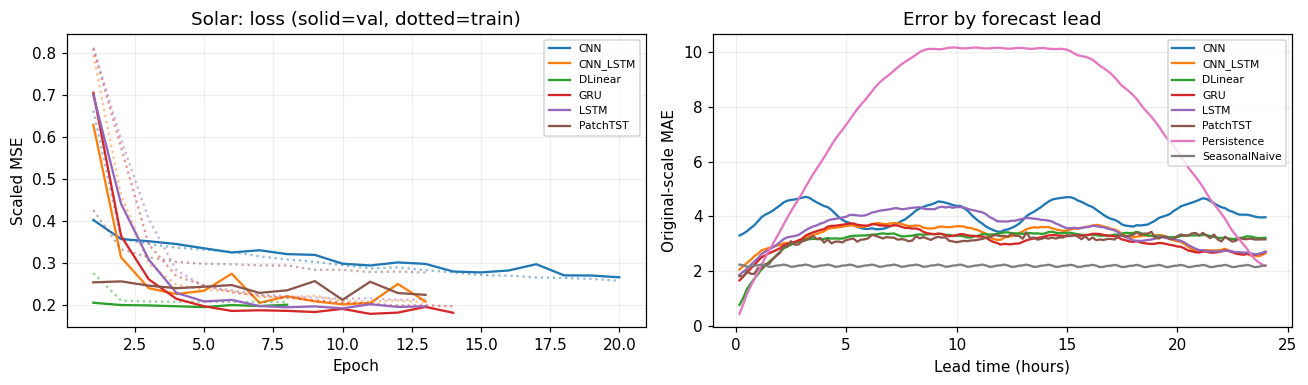

condition,active_output,first_4h,full_24h,low_output,weekday,weekend
model,,,,,,
CNN,6.234498,4.217653,4.098103,2.888099,4.051575,4.207329
CNN_LSTM,5.791673,2.903464,3.283134,1.861739,3.391953,3.027676
DLinear,5.370137,2.482560,3.175142,1.932615,3.162027,3.205930
GRU,5.523245,2.796412,3.130467,1.774631,3.212840,2.937092
LSTM,5.814170,2.981308,3.524112,2.226530,3.572685,3.410085
PatchTST,5.817016,2.617612,3.117457,1.587899,3.114004,3.125564
Persistence,11.586381,3.505219,7.379444,4.994158,7.067209,8.112428
SeasonalNaive,5.765044,2.202167,2.197647,0.176701,2.164028,2.276569


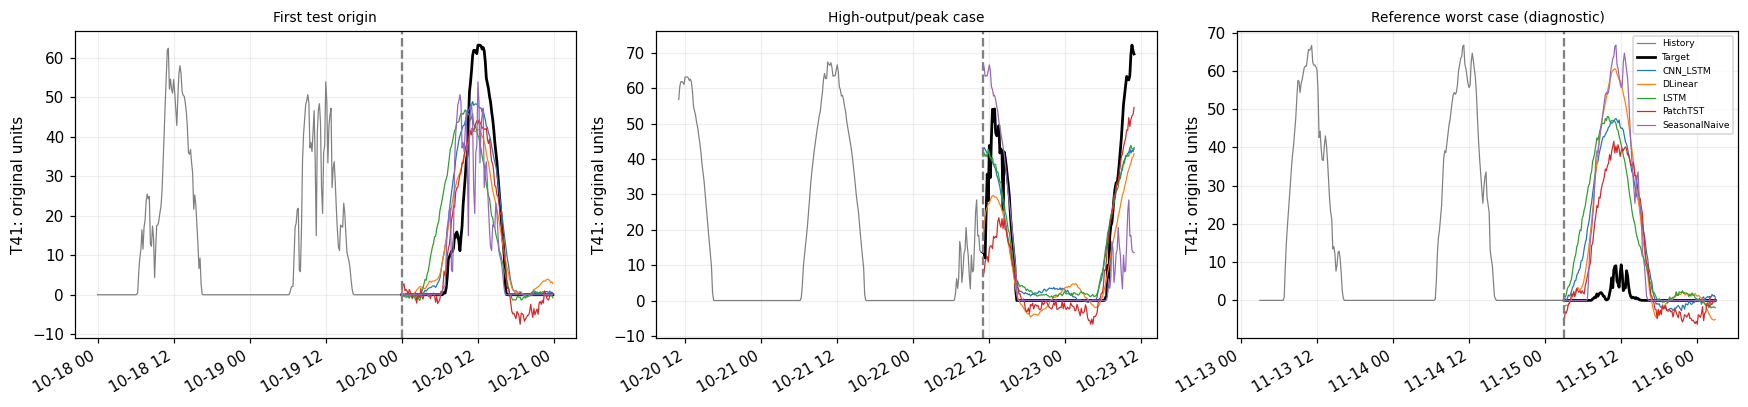

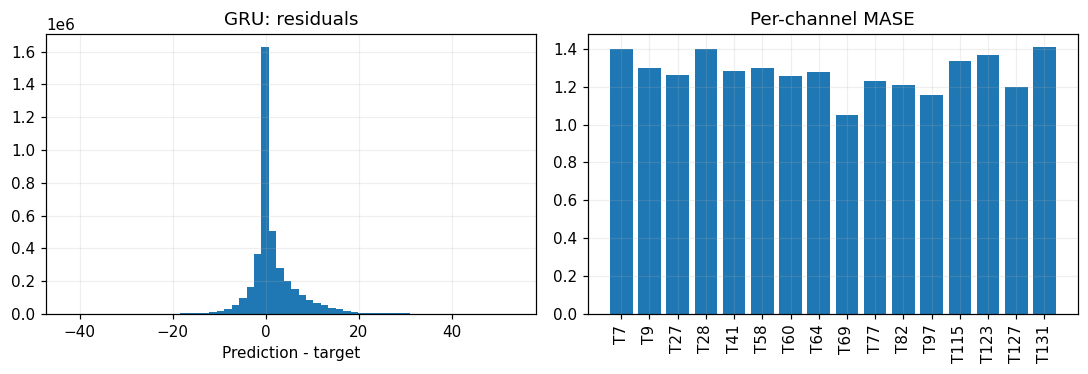

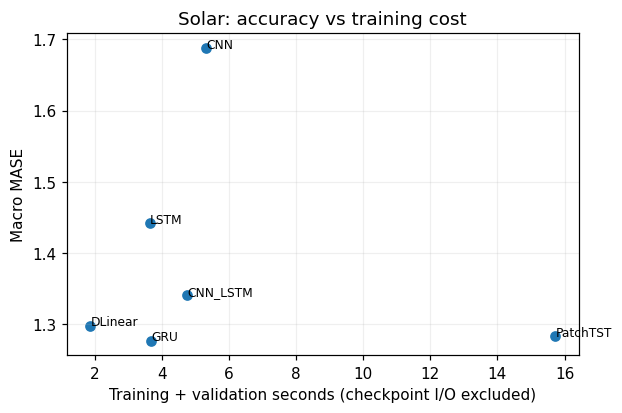

In [17]:
def collect_results():
    records=[json.loads(p.read_text()) for p in (OUTPUT_ROOT/'runs').glob('*/result.json')]
    return pd.DataFrame(records)

def load_run_arrays(row):
    data=np.load(Path(row['run_path'])/'predictions.npz')
    pred=data['prediction'];origins=data['origins']
    raw=DATA[row['dataset']]['raw'];H=int(row['H'])
    true=np.stack([raw[t:t+H] for t in origins])
    return pred,true,origins

def core_rows(name):
    r=collect_results()
    if r.empty:return r
    wanted=[]
    for model in ['Persistence','SeasonalNaive']+CORE_MODELS:
        spec=run_spec(model,CORE_CONTEXTS[name],42,'core',TRAIN_CFG)
        digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
        wanted.append(f'{name}_{model}_core_s42_{digest}')
    return r[r.experiment_id.isin(wanted)].sort_values('model')

for name in DATASETS_TO_RUN:
    rows=core_rows(name)
    if rows.empty:
        print(name,': no completed core results');continue
    columns=['model','MAE','RMSE','MASE','first4h_MAE','parameters','train_seconds','epochs']
    table=rows.reindex(columns=columns).set_index('model').reindex(['Persistence','SeasonalNaive']+CORE_MODELS)
    table['status']=np.where(table.MAE.notna(),'completed','missing')
    display(table);table.to_csv(OUTPUT_ROOT/'tables'/f'{name}_core_comparison.csv')
    fig,axs=plt.subplots(1,2,figsize=(12,3.6))
    for _,r in rows.iterrows():
        hist_path=Path(r.run_path)/'history.csv'
        if hist_path.exists():
            hist=pd.read_csv(hist_path)
            line=axs[0].plot(hist.epoch,hist.val_MSE,label=r.model)[0]
            axs[0].plot(hist.epoch,hist.train_MSE,color=line.get_color(),ls=':',alpha=.5)
        lead=pd.read_csv(Path(r.run_path)/'lead_time.csv');axs[1].plot(lead.lead_hours,lead.MAE,label=r.model)
    axs[0].set(title=f'{name}: loss (solid=val, dotted=train)',xlabel='Epoch',ylabel='Scaled MSE')
    axs[1].set(title='Error by forecast lead',xlabel='Lead time (hours)',ylabel='Original-scale MAE')
    for ax in axs:
        if ax.lines:ax.legend(fontsize=7)
    fig.tight_layout();save_figure(fig,f'{name}_learning_and_leadtime')
    conditions=[]
    for _,r in rows.iterrows():
        tab=pd.read_csv(Path(r.run_path)/'conditional.csv');tab['model']=r.model;conditions.append(tab)
    combined=pd.concat(conditions,ignore_index=True)
    combined.to_csv(OUTPUT_ROOT/'tables'/f'{name}_core_conditions.csv',index=False)
    display(combined.pivot(index='model',columns='condition',values='MAE'))
    learned=rows[rows['model'].isin(CORE_MODELS)].copy()
    if not learned.empty:
        # 使用验证损失选择用于诊断的参照模型，不用测试分数选择。
        reference=learned.sort_values('best_val_MSE').iloc[0]
        refpred,true,origins=load_run_arrays(reference)
        target=DATA[name]['raw'];test_start=DATA[name]['b2']
        c=int(np.argmax(target[:DATA[name]['b1']].std(axis=0)))
        event_score=true[:,:,c].max(axis=1)
        worst=np.abs(refpred-true).mean(axis=(1,2)).argmax()
        chosen=[0,int(event_score.argmax()),int(worst)]
        fig,axs=plt.subplots(1,3,figsize=(16,3.8))
        labels=['First test origin','High-output/peak case','Reference worst case (diagnostic)']
        plot_models=['SeasonalNaive','LSTM','CNN_LSTM','DLinear','PatchTST']
        arrays={r.model:load_run_arrays(r) for _,r in rows.iterrows() if r.model in plot_models}
        L=int(reference.L);H=int(reference.H)
        for ax,i,title in zip(axs,chosen,labels):
            t=int(origins[i]);idx=DATA[name]['index']
            ax.plot(idx[t-L:t],target[t-L:t,c],color='gray',lw=.8,label='History')
            ax.plot(idx[t:t+H],true[i,:,c],color='black',lw=1.8,label='Target')
            for model,(p,_,os_) in arrays.items():
                assert np.array_equal(os_,origins)
                ax.plot(idx[t:t+H],p[i,:,c],lw=.8,label=model)
            ax.axvline(idx[t],color='gray',ls='--');ax.set_title(title,fontsize=9)
            ax.set_ylabel(f'{DATA[name]["spec"]["ids"][c]}: original units')
        axs[-1].legend(fontsize=6);fig.autofmt_xdate();fig.tight_layout()
        save_figure(fig,f'{name}_forecast_cases')
        # 残差与通道分布：覆盖全部测试起点，不只最佳案例。
        fig,axs=plt.subplots(1,2,figsize=(10,3.5))
        axs[0].hist((refpred-true).ravel(),bins=60);axs[0].set(title=f'{reference.model}: residuals',xlabel='Prediction - target')
        per=pd.read_csv(Path(reference.run_path)/'per_channel.csv')
        axs[1].bar(per.series_id,per.MASE);axs[1].tick_params(axis='x',rotation=90);axs[1].set(title='Per-channel MASE')
        fig.tight_layout();save_figure(fig,f'{name}_residuals_channels')
    timing=rows[rows['model'].isin(CORE_MODELS)]
    if not timing.empty:
        fig,ax=plt.subplots(figsize=(6,3.8))
        ax.scatter(timing.train_seconds,timing.MASE)
        for _,r in timing.iterrows():ax.annotate(r.model,(r.train_seconds,r.MASE),fontsize=8)
        ax.set(title=f'{name}: accuracy vs training cost',xlabel='Training + validation seconds (checkpoint I/O excluded)',ylabel='Macro MASE')
        save_figure(fig,f'{name}_accuracy_cost')


## 10. 后续实验开关（默认均关闭）
只用验证集调整配置。保持 test 目标区间和固定 ID 不变。
- **多种子**：核心学习模型使用 42/123/2026，报告均值与标准差，不挑最佳 seed。
- **历史长度**：24/48/168 小时；三个设置共同使用最长窗口可用的训练/评价起点。
- **数据量**：末尾连续 25/50/100% 训练片段，每个片段独立拟合 scaler。
- **消融**：CNN–LSTM vs 移除 CNN 前端的 LSTM；容量未完全匹配，必须说明。

长 Solar 窗口请先做试运行。若 OOM，记录后调整整个敏感性组的 batch size；不要静默删模型或换测试集。
数据量同时改变季节覆盖和 update 数量，不将其解释为纯样本数量因果效应。


In [18]:
SENS_CFG=dict(TRAIN_CFG)
# 初始仍使用核心 batch；若最长 Solar 窗口 OOM，按验证出的资源限制统一调整。
plan=dict(repeat_seeds=SEEDS,history_hours=[24,48,168],fractions=[.25,.5,1.],
          models=['LSTM','PatchTST'],history_common_hours=168,config=SENS_CFG,
          note='Predeclared plan. Do not tune on test results.')
plan_path=OUTPUT_ROOT/'optional_experiment_plan.json'
if plan_path.exists():
    if any([RUN_REPEATS,RUN_HISTORY,RUN_DATA_FRACTION,RUN_ABLATION]):
        assert json.loads(plan_path.read_text())==clean_json(plan), 'Plan differs: explicitly version output folder before changing.'
else:write_json(plan_path,plan)

if RUN_REPEATS:
    for name in DATASETS_TO_RUN:
        for seed in SEEDS:
            for model in CORE_MODELS:
                run_experiment(model,CORE_CONTEXTS[name],seed=seed,stage='core')
if RUN_HISTORY:
    for name in DATASETS_TO_RUN:
        for hours in plan['history_hours']:
            ctx=prepare_context(name,history_hours=hours,common_history_hours=168)
            for model in plan['models']:
                run_experiment(model,ctx,seed=42,stage='history',cfg=SENS_CFG)
if RUN_DATA_FRACTION:
    for name in DATASETS_TO_RUN:
        for fraction in plan['fractions']:
            ctx=prepare_context(name,train_fraction=fraction)
            for model in plan['models']:
                run_experiment(model,ctx,seed=42,stage='data_fraction',cfg=SENS_CFG)
if RUN_ABLATION:
    for name in DATASETS_TO_RUN:
        for model in ['CNN_LSTM','CNN_LSTM_noCNN']:
            run_experiment(model,CORE_CONTEXTS[name],seed=42,stage='ablation')
if not any([RUN_REPEATS,RUN_HISTORY,RUN_DATA_FRACTION,RUN_ABLATION]):
    print('Optional experiments skipped. Enable the relevant flag and rerun this cell later.')


Optional experiments skipped. Enable the relevant flag and rerun this cell later.


## 11. 全部结果汇总、重复实验与导出
均值/标准差按同一配置分组，不能把不同数据/窗口混成一个分数。
结果数据库只存元数据、指标和文件路径，checkpoint/预测数组独立存放。
课程优先考虑 vector database；当前 SQLite 记录不等同于满足向量检索要求，需按 rubric 决定是否补充真实用途。


In [19]:
results=collect_results()
if not results.empty:
    results.to_csv(OUTPUT_ROOT/'tables'/'all_completed_experiments.csv',index=False)
    core=results[results.stage=='core']  # comparison_key 排除seed，但包含全部配置/划分/版本
    assert 'comparison_key' in core.columns, 'Old result format: use a fresh versioned output folder.'
    repeat=core.groupby(['dataset','model','history_hours','train_fraction','comparison_key']).agg(
        n_runs=('seed','nunique'),MAE_mean=('MAE','mean'),MAE_std=('MAE','std'),
        RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MASE_mean=('MASE','mean'),MASE_std=('MASE','std'))
    repeat.to_csv(OUTPUT_ROOT/'tables'/'core_seed_summary.csv');display(repeat)
    for stage,xcol,title in [('history','history_hours','History-length sensitivity'),
                             ('data_fraction','train_fraction','Training-data sensitivity')]:
        subset=results[results.stage==stage]
        for name in DATASETS_TO_RUN:
            rows=subset[subset.dataset==name]
            if rows.empty:continue
            fig,axs=plt.subplots(1,2,figsize=(10,3.5))
            # 不把旧环境/配置的结果混入当前可选实验图。
            wanted=[]
            for value in plan['history_hours' if stage=='history' else 'fractions']:
                c=prepare_context(name,history_hours=value,common_history_hours=168) if stage=='history' else prepare_context(name,train_fraction=value)
                for model in plan['models']:
                    spec=run_spec(model,c,42,stage,SENS_CFG)
                    digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
                    wanted.append(f'{name}_{model}_{stage}_s42_{digest}')
            rows=rows[rows.experiment_id.isin(wanted)]
            if rows.empty:
                plt.close(fig);continue
            for model,g in rows.groupby('model'):
                g=g.sort_values(xcol)
                axs[0].plot(g[xcol],g.MASE,'o-',label=model)
                axs[1].plot(g[xcol],g.train_seconds,'o-',label=model)
            axs[0].set(title=title+' (MASE)',xlabel=xcol,ylabel='Macro MASE')
            axs[1].set(title='Training cost',xlabel=xcol,ylabel='Seconds')
            for ax in axs:ax.legend(fontsize=8)
            fig.tight_layout();save_figure(fig,f'{name}_{stage}')
    display(results[['dataset','model','stage','seed','history_hours','train_fraction','MAE','MASE']])
with sqlite3.connect(DB_PATH) as conn:
    status=pd.read_sql_query('SELECT experiment_id,status,updated FROM experiments',conn)
status.to_csv(OUTPUT_ROOT/'tables'/'experiment_status.csv',index=False);display(status)
print('Outputs:',OUTPUT_ROOT)

# 小型报告包包含配置、CSV、图和数据库；不包含大的 checkpoint/预测数组。
import shutil
package_dir=LOCAL_ROOT/'report_bundle'
if package_dir.exists():shutil.rmtree(package_dir)
package_dir.mkdir(parents=True)
for folder in ['figures','tables']:
    shutil.copytree(OUTPUT_ROOT/folder,package_dir/folder)
for p in OUTPUT_ROOT.glob('*.json'):shutil.copy2(p,package_dir/p.name)
# 使用 SQLite backup 生成一致的数据库快照，而不是直接复制活动连接。
with sqlite3.connect(DB_PATH) as src, sqlite3.connect(package_dir/'experiments.sqlite') as dst:src.backup(dst)
for p in (OUTPUT_ROOT/'runs').glob('*/config.json'):
    dest=package_dir/'run_configs'/p.parent.name;dest.mkdir(parents=True,exist_ok=True);shutil.copy2(p,dest/'config.json')
zip_path=shutil.make_archive(str(LOCAL_ROOT/'LDI_report_bundle'),'zip',package_dir)
print('Report bundle:',zip_path)
# 可手动取消注释下载；Drive 中的完整 runs 另行保留。
# if IN_COLAB:
#     from google.colab import files
#     files.download(zip_path)


n_runs  \
dataset     model         history_hours train_fraction comparison_key             
Electricity CNN           48            1.0            115cbe95403aca30       1   
            CNN_LSTM      48            1.0            08549c1dcf27bcd1       1   
            DLinear       48            1.0            1b253ec8178bf083       1   
            GRU           48            1.0            b4bcbd38aadacc62       1   
            LSTM          48            1.0            c02b2424c8d8eb0f       1   
            PatchTST      48            1.0            e97c45eb8ed3e12a       1   
            Persistence   48            1.0            c79ede8f593569f7       1   
            SeasonalNaive 48            1.0            a926a99d3d127971       1   
Solar       CNN           48            1.0            c0fbe97a119d1e31       1   
            CNN_LSTM      48            1.0            fd6c5fa2f4e43cbc       1   
            DLinear       48            1.0            5de69738bd394fca       1   
            GRU           48            1.0            4875a2fe3d56e2d8       1   
            LSTM          48            1.0            1a38e6ed4106f04c       1   
            PatchTST      48            1.0            7904a637dd647129       1   
            Persistence   48            1.0            070009365141dd39       1   
            SeasonalNaive 48            1.0            2c49ff9a10395063       1   

                                                                            MAE_mean  \
dataset     model         history_hours train_fraction comparison_key                  
Electricity CNN           48            1.0            115cbe95403aca30   255.728609   
            CNN_LSTM      48            1.0            08549c1dcf27bcd1   266.288502   
            DLinear       48            1.0            1b253ec8178bf083   210.343758   
            GRU           48            1.0            b4bcbd38aadacc62   252.333278   
            LSTM          48            1.0            c02b2424c8d8eb0f   258.517937   
            PatchTST      48            1.0            e97c45eb8ed3e12a   229.868157   
            Persistence   48            1.0            c79ede8f593569f7  1010.260635   
            SeasonalNaive 48            1.0            a926a99d3d127971   208.217971   
Solar       CNN           48            1.0            c0fbe97a119d1e31     4.098103   
            CNN_LSTM      48            1.0            fd6c5fa2f4e43cbc     3.283134   
            DLinear       48            1.0            5de69738bd394fca     3.175142   
            GRU           48            1.0            4875a2fe3d56e2d8     3.130467   
            LSTM          48            1.0            1a38e6ed4106f04c     3.524112   
            PatchTST      48            1.0            7904a637dd647129     3.117457   
            Persistence   48            1.0            070009365141dd39     7.379444   
            SeasonalNaive 48            1.0            2c49ff9a10395063     2.197647   

                                                                         MAE_std  \
dataset     model         history_hours train_fraction comparison_key              
Electricity CNN           48            1.0            115cbe95403aca30      NaN   
            CNN_LSTM      48            1.0            08549c1dcf27bcd1      NaN   
            DLinear       48            1.0            1b253ec8178bf083      NaN   
            GRU           48            1.0            b4bcbd38aadacc62      NaN   
            LSTM          48            1.0            c02b2424c8d8eb0f      NaN   
            PatchTST      48            1.0            e97c45eb8ed3e12a      NaN   
            Persistence   48            1.0            c79ede8f593569f7      NaN   
            SeasonalNaive 48            1.0            a926a99d3d127971      NaN   
Solar       CNN           48            1.0            c0fbe97a119d1e31      NaN   
            CNN_LSTM      48            1.0            fd6c5fa2f4e43c

,dataset,model,stage,seed,history_hours,train_fraction,MAE,MASE
0,Electricity,Persistence,core,42,48,1.0,1010.260635,3.630473
1,Electricity,SeasonalNaive,core,42,48,1.0,208.217971,1.008813
2,Electricity,LSTM,core,42,48,1.0,258.517937,1.246911
3,Electricity,GRU,core,42,48,1.0,252.333278,1.247105
4,Electricity,CNN,core,42,48,1.0,255.728609,1.261648
5,Electricity,CNN_LSTM,core,42,48,1.0,266.288502,1.300423
6,Electricity,DLinear,core,42,48,1.0,210.343758,0.984451
7,Electricity,PatchTST,core,42,48,1.0,229.868157,1.026148
8,Solar,Persistence,core,42,48,1.0,7.379444,3.047881
9,Solar,SeasonalNaive,core,42,48,1.0,2.197647,0.899621


,experiment_id,status,updated
0,Electricity_Persistence_core_s42_80f32c5513e3,completed,2026-10-14T05:34:50.093515+00:00
1,Electricity_SeasonalNaive_core_s42_71e6f97333ec,completed,2026-10-14T05:34:50.671819+00:00
2,Electricity_LSTM_core_s42_8059c074198b,completed,2026-10-14T05:35:13.676101+00:00
3,Electricity_GRU_core_s42_32030ed621a8,completed,2026-10-14T05:35:28.920248+00:00
4,Electricity_CNN_core_s42_d4fc30018837,completed,2026-10-14T05:35:41.292231+00:00
5,Electricity_CNN_LSTM_core_s42_ae90754d4284,completed,2026-10-14T05:35:59.625784+00:00
6,Electricity_DLinear_core_s42_99573a5fa39d,completed,2026-10-14T05:36:13.563388+00:00
7,Electricity_PatchTST_core_s42_1fa4a3ac0229,completed,2026-10-14T05:36:34.813578+00:00
8,Solar_Persistence_core_s42_973824f40c49,completed,2026-10-14T05:36:35.894602+00:00
9,Solar_SeasonalNaive_core_s42_6eac5c4bde8e,completed,2026-10-14T05:36:37.007845+00:00


Outputs: /content/drive/MyDrive/LDI_Project/results_v1
Report bundle: /content/ldi_work/LDI_report_bundle.zip


## 12. 报告填写与结论检查
| 报告内容 | 对应输出 | 需要解释 |
|---|---|---|
| 数据/EDA | data_audit、training_statistics、eda 图 | 周期、零值、子集限制、来源 |
| 实验设置 | config、environment、scaler、SQLite | 划分、起点、信息公平性、验证选择 |
| 模型对比 | core_comparison、history、forecast_cases | 基线是否足够强，混合/现代模型是否值得成本 |
| 工程误差 | conditional、lead_time、residuals_channels | 峰值、活跃出力、远期和失败场景 |
| 第 4 部分 | history/data_fraction/ablation 的结果 | 收益、容量和季节覆盖混杂因素 |
| 稳定性 | core_seed_summary | 单种子仅初步结果；std 不是显著性证明 |

不要把整体 Solar 误差低解释成活跃时段也准确；不要把 active-output 称为真正白天。
MASE < 1 不是自动击败 test Seasonal Naive 的证明，要直接比较参考结果。
当前验证最优模型的失败图是事后诊断，不能只展示好看的窗口。
文献机制解释需引用 primary papers；本 notebook 只提供实验证据。

### 复现与故障处理
- `ModuleNotFoundError`：运行第 0–1 节；不要安装整个仓库所有可选模型依赖。
- 下载失败：检查网络后重跑第 2 节；临时下载文件不会被当成完整 ZIP。
- GPU OOM：记录配置后统一降低 batch size；变化生成新 run ID，不复用不同配置结果。
- Colab 断线：重新挂载相同 Drive 路径，运行定义单元，再执行训练单元；按 epoch 恢复。
- 只重画图：`RUN_CORE=False`，关闭可选开关，加载同一结果目录后运行分析。
- 新增网络代码：递增 `IMPLEMENTATION_VERSION` 或使用新结果目录，避免误跳过旧结果。

来源：[Monash](https://forecastingdata.org/)、[数据读取代码](https://github.com/rakshitha123/TSForecasting)、
[Time-Series-Library](https://github.com/thuml/Time-Series-Library)。


### 交付前验证范围
已用两套原始数据的小量窗口，在 CPU 环境检查六个模型的前向、两轮训练、指标、图表和导出；另检查最长 Solar 输入、比例/消融路径，以及模拟 epoch 中断恢复。Notebook schema 与所有代码单元语法通过检查。未在 Colab T4 上执行全量训练，运行时间、CUDA兼容性和正式分数仍需你们实际运行确认。检查分数不作为项目结果，所有交付代码单元输出为空。
